In [63]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from rpa_control.paths import save_fig

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Panel B: fold-change detector, u: 1 → 2 → 4

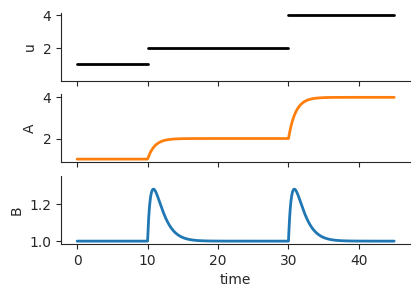

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_B.pdf


In [64]:


# ── Fold-change detector ─────────────────────────────────────────────
# dA/dt = X - A      (A tracks X)
# dB/dt = X/A - B    (B senses X/A; B* = 1 at any X)
def fcd_rhs(t, state, X_of_t):
    A, B = state
    X = X_of_t(t)
    return [X - A, X / A - B]

# Piecewise X: 1 → 2 → 4
t1, t2, t_end = 10.0, 30.0, 45.0
def u_of_t(t):
    if t < t1: return 1.0
    if t < t2: return 2.0
    return 4.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 1.0, 1.0
sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t,), max_step=0.05, rtol=1e-8, atol=1e-10)
A = sol.y[0]
B = sol.y[1]


# ── Plot ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(4.5, 3), sharex=True)

# u: 
ax = axes[0]
lw = 2
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment, [u_of_t(segment[0]+0.01), u_of_t(segment[1]-0.01)], lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

# A:
ax = axes[1]
ax.plot(t, A, lw=lw, color='C1')
ax.set_ylabel('A')
ax.set_yticks([2, 4])

# B:
ax = axes[2]
ax.plot(t, B, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(top=1.35)

for ax in axes:
    sns.despine(ax=ax)

plt.show()


save_fig(fig, 'figure5_B.pdf')


# Panel C: standard vs. slingshot

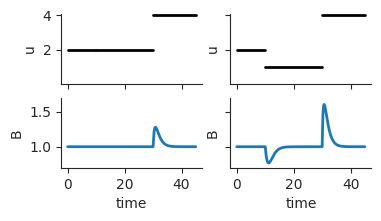

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_C.pdf


In [65]:


# Standard (u: 2 → 4) vs slingshot (u: 2 → 1 → 4)
t1, t2, t_end = 10.0, 30.0, 45.0




# ── Plot ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(4, 2), sharex=True, sharey='row')


# standard:
def u_of_t(t):
    if t < t1: return 2.0
    if t < t2: return 2.0
    return 4.0


t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0
sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t,), max_step=0.05, rtol=1e-8, atol=1e-10)
A = sol.y[0]
B = sol.y[1]


# u standard: 
ax = axes[0,0]
lw = 2
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment, [u_of_t(segment[0]+0.01), u_of_t(segment[1]-0.01)], lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

# B standard:
ax = axes[1,0]
ax.plot(t, B, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)



# slingshot:
def u_of_t_slingshot(t):
    if t < t1: return 2.0
    if t < t2: return 1.0
    return 4.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0
sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05, rtol=1e-8, atol=1e-10)
A_slingshot = sol.y[0]
B_slingshot = sol.y[1]


# u slingshot: 
ax = axes[0,1]
lw = 2
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment, [u_of_t_slingshot(segment[0]+0.01), u_of_t_slingshot(segment[1]-0.01)], lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

# B slingshot:
ax = axes[1,1]
ax.plot(t, B_slingshot, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)



for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()


save_fig(fig, 'figure5_C.pdf')


# Panel D: abrupt vs. gradual slingshot

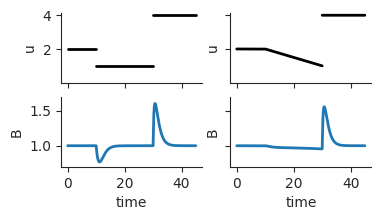

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_D.pdf


In [66]:
# Slingshot step vs slow ramp from 2 → 1
t1, t2, t_end = 10.0, 30.0, 45.0


# ── Plot ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(4, 2),
                         sharex=True, sharey='row')

lw = 2

# ── Left: slingshot (abrupt step down then up) ──────────────────────
def u_of_t_slingshot(t):
    if t < t1: return 2.0
    if t < t2: return 1.0
    return 4.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0
sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_slingshot,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_slingshot = sol.y[1]

ax = axes[0, 0]
for segment in [(0, t1), (t1, t2), (t2, t_end)]:
    ax.plot(segment,
            [u_of_t_slingshot(segment[0] + 0.01),
             u_of_t_slingshot(segment[1] - 0.01)],
            lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

ax = axes[1, 0]
ax.plot(t, B_slingshot, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)


# ── Right: ramp from 2 → 1 over [t1, t2], then jump to 4 ────────────
def u_of_t_ramp(t):
    if t < t1: return 2.0
    if t < t2: return 2.0 + (1.0 - 2.0) * (t - t1) / (t2 - t1)
    return 4.0

t = np.linspace(0, t_end, 6000)
A0, B0 = 2.0, 1.0
sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                args=(u_of_t_ramp,), max_step=0.05,
                rtol=1e-8, atol=1e-10)
B_ramp = sol.y[1]

ax = axes[0, 1]
u_ramp_vals = np.array([u_of_t_ramp(tt) for tt in t])
u_plot = u_ramp_vals.copy()
u_plot[np.isclose(t, t2, atol=t[1] - t[0])] = np.nan
ax.plot(t, u_plot, lw=lw, color='k')
ax.set_ylabel('u')
ax.set_yticks([2, 4])
ax.set_ylim(bottom=0)

ax = axes[1, 1]
ax.plot(t, B_ramp, lw=lw, color='C0')
ax.set_ylabel('B')
ax.set_xlabel('time')
ax.set_ylim(bottom=0.7, top=1.7)


for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()

save_fig(fig, 'figure5_D.pdf')


# Panel E: three strategies under three cancer growth functions

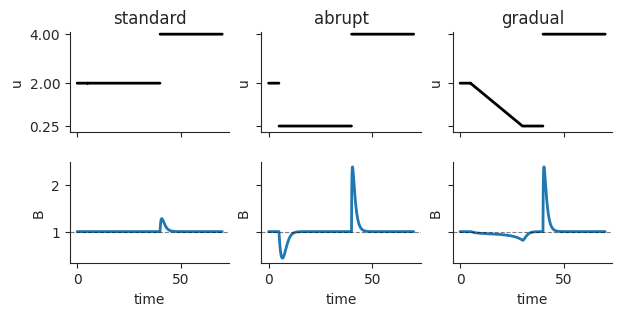

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_E_uB.pdf


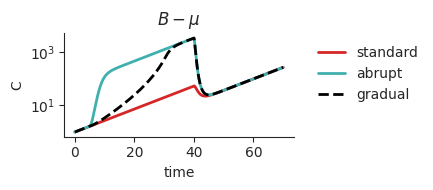

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_E_C_kernel_B-mu.pdf


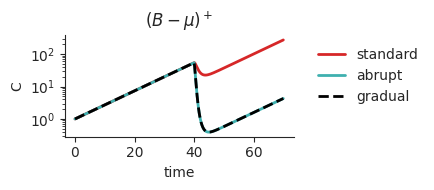

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_E_C_kernel_B-muplus.pdf


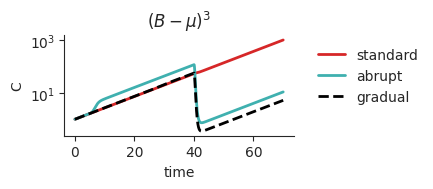

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_E_C_kernel_B-mu3.pdf


In [67]:
# Three strategies × three killing kernels
t1, t2, t_end = 5.0, 40.0, 70.0
t_ramp_end = t2 - 10.0
c1, c2, mu = 0.1, 2, 1
C0 = 1.0
A0, B0 = 2.0, 1.0
slingshot_u = 0.25


def make_integrate_C(kernel):
    def integrate(t, B):
        def f(tt, C):
            B_t = np.interp(tt, t, B)
            return C[0] * (c1 - c2 * kernel(B_t - mu))
        sol = solve_ivp(f, [t[0], t[-1]], [C0], t_eval=t,
                        max_step=0.05, rtol=1e-8, atol=1e-10)
        return sol.y[0]
    return integrate


kernels = [
    (r'$B - \mu$',           lambda x: x),
    (r'$(B - \mu)^+$',       lambda x: max(x, 0.0)),
    (r'$(B - \mu)^3$',       lambda x: x ** 3),
]


def u_standard(tt):
    if tt < t2: return 2.0
    return 4.0

def u_abrupt(tt):
    if tt < t1: return 2.0
    if tt < t2: return slingshot_u
    return 4.0

def u_gradual(tt):
    if tt < t1: return 2.0
    if tt < t_ramp_end:
        return 2.0 + (slingshot_u - 2.0) * (tt - t1) / (t_ramp_end - t1)
    if tt < t2: return slingshot_u
    return 4.0


strategies = [
    ('standard', u_standard, 'C3'),
    ('abrupt',   u_abrupt,   '#3FB0AF'),
    ('gradual',  u_gradual,  'k'),
]

t = np.linspace(0, t_end, 6000)

# Simulate B once per strategy (kernel only affects C)
strategy_data = {}
for name, u_fn, color in strategies:
    sol = solve_ivp(fcd_rhs, [0, t_end], [A0, B0], t_eval=t,
                    args=(u_fn,), max_step=0.05,
                    rtol=1e-8, atol=1e-10)
    B = sol.y[1]
    u_vals = np.array([u_fn(tt) for tt in t])
    strategy_data[name] = dict(u=u_vals, B=B, color=color)


# ── Top figure: 2 rows × 3 cols (u, B) ──────────────────────────────
lw = 2
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(7, 3),
                         sharex=True, sharey='row',
                         gridspec_kw={'hspace': 0.3})

for col, (name, _, _) in enumerate(strategies):
    r = strategy_data[name]
    u_plot = r['u'].astype(float).copy()
    for t_jump in [t1, t2]:
        u_plot[np.isclose(t, t_jump, atol=t[1] - t[0])] = np.nan

    axes[0, col].plot(t, u_plot, lw=lw, color='k')
    axes[0, col].set_ylabel('u')
    axes[0, col].set_yticks([slingshot_u, 2, 4])
    axes[0, col].set_ylim(bottom=0)
    axes[0, col].set_title(name)

    axes[1, col].plot(t, r['B'], lw=lw, color='C0')
    axes[1, col].axhline(mu, color='k', linestyle='--', lw=0.8, alpha=0.5)
    axes[1, col].set_ylabel('B')
    axes[1, col].set_xlabel('time')

for ax in axes.flatten():
    sns.despine(ax=ax)

plt.show()
save_fig(fig, 'figure5_E_uB.pdf')


# ── Loop over kernels: one C plot per kernel ────────────────────────
for kernel_label, kernel_fn in kernels:
    integrate_C = make_integrate_C(kernel_fn)

    fig_C, ax = plt.subplots(figsize=(4.5, 2))
    for name, _, _ in strategies:
        r = strategy_data[name]
        C = integrate_C(t, r['B'])
        linestyle = '--' if name == 'gradual' else '-'
        ax.plot(t, C, lw=lw, color=r['color'], label=name, linestyle=linestyle)

    ax.set_xlabel('time')
    ax.set_ylabel('C')
    ax.set_yscale('log')
    ax.set_title(f'{kernel_label}')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)
    sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

    safe = kernel_label.replace('$', '').replace('\\', '').replace(' ', '').replace('^', '').replace('(', '').replace(')', '').replace('+', 'plus')
    save_fig(fig_C, f'figure5_E_C_kernel_{safe}.pdf')


# SI: phase portraits of the type-1 IFFL

$$\frac{dx}{dt} = \alpha\,u - \delta\,x \qquad \frac{dy}{dt} = \beta\,u - \gamma\,x\,y \qquad x_{ss} = \frac{\alpha\,u}{\delta}, \quad y_{ss} = \frac{\beta\,\delta}{\gamma\,\alpha}$$

$y_{ss}$ is independent of $u$ (robust perfect adaptation). Nullclines: $\dot{x}=0 \Rightarrow x = u$ (vertical); $\dot{y}=0 \Rightarrow y = u/x$ (hyperbola), intersecting at $(u,\,1)$.

Note: these are portraits of the type-1 IFFL (`iffl_rhs` below), not of the fold-change detector `fcd_rhs` used in panels B–E. Collected from `OLD/figure_iffl_v1`, `OLD/iffl2vars_control_strategies` and `OLD/test_iffl`.

In [68]:
"""Shared parameters, ODE and plotting helpers for the type-1 IFFL phase portraits."""
from rpa_control.style import set_style

set_style()
plt.rcParams['text.usetex'] = False


def clean_ax(ax):
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)


PARAMS = dict(alpha=1.0, delta=1.0, beta=1.0, gamma=1.0)

def steady_state(u, p=PARAMS):
    x_ss = p['alpha'] * u / p['delta']
    y_ss = p['beta'] * p['delta'] / (p['gamma'] * p['alpha'])
    return x_ss, y_ss

def iffl_rhs(y_state, u, p=PARAMS):
    x, y = y_state
    dx_dt = p['alpha'] * u - p['delta'] * x
    dy_dt = p['beta'] * u - p['gamma'] * x * y
    return np.array([dx_dt, dy_dt])


# ── Streamline-style helpers (replace python-control's phase_plane_plot / streamlines) ──
def draw_field(ax, u, limits, color='lightgray'):
    """Background vector field of the IFFL at constant u over limits = [x0, x1, y0, y1]."""
    x0, x1, y0, y1 = limits
    X, Y = np.meshgrid(np.linspace(x0, x1, 200), np.linspace(y0, y1, 200))
    DX, DY = iffl_rhs([X, Y], u)
    ax.streamplot(X, Y, DX, DY, color=color, linewidth=1.1, density=1.0, arrowsize=1.0)

def draw_trajectory(ax, u, x0, t_end=10.0, color='b', label=None, n_arrows=4):
    """Trajectory from x0 under constant u, with up to n_arrows arrows spaced along its arc length."""
    sol = solve_ivp(lambda t_, s: iffl_rhs(s, u), [0, t_end], x0,
                    t_eval=np.linspace(0, t_end, 1000), max_step=0.05)
    xs, ys = sol.y
    line, = ax.plot(xs, ys, color=color, lw=1.2, label=label)
    cumlen = np.concatenate([[0], np.cumsum(np.hypot(np.diff(xs), np.diff(ys)))])
    n = min(n_arrows, int(cumlen[-1] / 0.3) + 1) if cumlen[-1] > 1e-6 else 0
    for k in range(1, n + 1):
        i = min(np.searchsorted(cumlen, k / (n + 1) * cumlen[-1]), len(xs) - 2)
        ax.annotate('', xy=(xs[i + 1], ys[i + 1]), xytext=(xs[i], ys[i]),
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.2))
    return line

### Phase portraits for u = 0.5, 1, 2

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_u_values.pdf


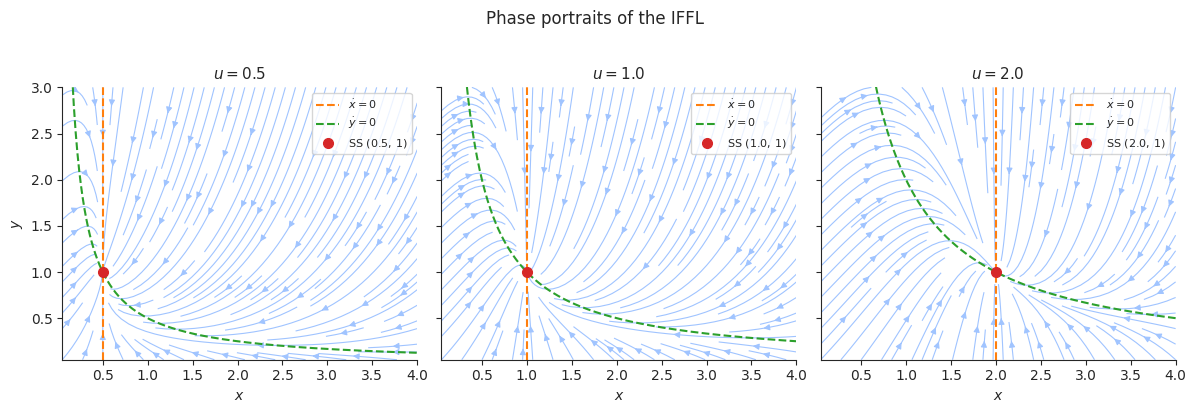

In [69]:
# Phase portraits for u = 0.5, 1, 2
U_VALS = [0.5, 1.0, 2.0]

X_LIM = (0.05, 4.0)
Y_LIM = (0.05, 3.0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)

for ax, u in zip(axes, U_VALS):
    x_ss, y_ss = steady_state(u)

    x_range = np.linspace(*X_LIM, 300)
    y_range = np.linspace(*Y_LIM, 300)
    X, Y = np.meshgrid(x_range, y_range)
    DX = PARAMS['alpha'] * u - PARAMS['delta'] * X
    DY = PARAMS['beta']  * u - PARAMS['gamma'] * X * Y

    ax.streamplot(X, Y, DX, DY, density=1.2, linewidth=0.8,
                  color='#a0c4ff', arrowsize=0.9)

    ax.axvline(u, color='C1', lw=1.5, ls='--', label=r'$\dot{x}=0$')

    xnc = np.linspace(X_LIM[0], X_LIM[1], 400)
    ax.plot(xnc, u / xnc, color='C2', lw=1.5, ls='--', label=r'$\dot{y}=0$')

    ax.plot(x_ss, y_ss, 'o', color='C3', ms=7, zorder=5, label=rf'SS $({u:.1f},\,1)$')

    ax.set_xlim(*X_LIM)
    ax.set_ylim(*Y_LIM)
    ax.set_xlabel('$x$')
    ax.set_title(f'$u = {u}$', fontsize=11)
    ax.legend(fontsize=8, loc='upper right')
    clean_ax(ax)

axes[0].set_ylabel('$y$')
fig.suptitle('Phase portraits of the IFFL', fontsize=12, y=1.02)
plt.tight_layout()
save_fig(fig, 'figure5_SI_phase_u_values.pdf')
plt.show()

### u = 2: trajectories from the steady states of u = 0.5 and u = 1

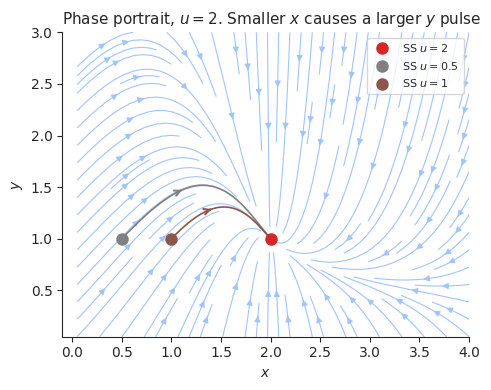

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_u2_from_two_SS.pdf


In [70]:
# Phase portrait for u=2 with trajectories starting from SS of u=0.5 and u=1
U_D = 2.0
T_END = 10.0
TRAJ_ICS    = [(0.5, 1.0), (1.0, 1.0)]
TRAJ_COLORS = ['gray', 'C5']
TRAJ_LABELS = [r'SS $u=0.5$', r'SS $u=1$']

X_LIM = (-0.1, 4.0)
Y_LIM = (0.05, 3.0)

fig, ax = plt.subplots(figsize=(5, 4))

x_range = np.linspace(0.05, X_LIM[1], 300)
y_range = np.linspace(*Y_LIM, 300)
X, Y = np.meshgrid(x_range, y_range)
DX = PARAMS['alpha'] * U_D - PARAMS['delta'] * X
DY = PARAMS['beta']  * U_D - PARAMS['gamma'] * X * Y

ax.streamplot(X, Y, DX, DY, density=1.2, linewidth=0.8,
              color='#a0c4ff', arrowsize=0.9)

# Steady state for u=2
x_ss, y_ss = steady_state(U_D)
ax.plot(x_ss, y_ss, 'o', color='C3', ms=8, zorder=6, label=r'SS $u=2$')

# Trajectories starting from SS of u=0.5 and u=1
t_eval = np.linspace(0, T_END, 500)
arrow_frac = 0.05
for (x0, y0), color, label in zip(TRAJ_ICS, TRAJ_COLORS, TRAJ_LABELS):
    sol = solve_ivp(
        lambda t_, y: iffl_rhs(y, U_D).tolist(),
        [0, T_END], [x0, y0], t_eval=t_eval, max_step=0.05)
    xs, ys = sol.y[0], sol.y[1]
    ax.plot(xs, ys, lw=1.2, color=color, zorder=5)
    ax.plot(xs[0], ys[0], 'o', color=color, ms=8, zorder=7, label=label)
    i = int(arrow_frac * len(xs))
    ax.annotate('', xy=(xs[i+1], ys[i+1]), xytext=(xs[i], ys[i]),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5),
                zorder=8)

ax.set_xlim(*X_LIM)
ax.set_ylim(*Y_LIM)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_title(r'Phase portrait, $u=2$. Smaller $x$ causes a larger $y$ pulse', fontsize=11, loc='left')
ax.legend(fontsize=8, loc='upper right')
clean_ax(ax)
plt.tight_layout()
plt.show()
save_fig(fig, 'figure5_SI_phase_u2_from_two_SS.pdf')

### u = 1 → 0.5: fast vs slow (stepped) transition

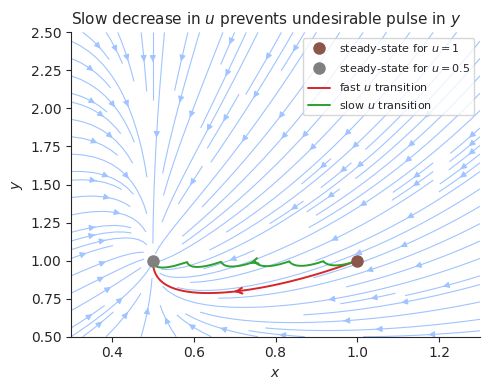

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_u05_fast_vs_slow.pdf


In [71]:
# Three ways to transition from u=1 → u=0.5 in phase space
T_TRANS = 30.0   # transition duration (gradual and small-jumps)
T_HOLD  = 10.0   # extra time to hold at u=0.5 after transition
T_END_E = T_TRANS + T_HOLD
N_JUMPS = 6      # number of discrete steps for the small-jumps case
X0, Y0  = 1.0, 1.0   # start = SS of u=1

X_LIM_E = (0.3, 1.3)
Y_LIM_E = (0.5, 2.5)

def simulate_transition(u_func, t_end, n_points=2000):
    t_eval = np.linspace(0, t_end, n_points)
    sol = solve_ivp(
        lambda t_, y: iffl_rhs(y, u_func(t_)).tolist(),
        [0, t_end], [X0, Y0], t_eval=t_eval, max_step=0.05)
    return sol.y[0], sol.y[1]

# 1. Instant jump
u_instant = lambda t: 0.5
xs_instant, ys_instant = simulate_transition(u_instant, T_END_E)

# 2. Small discrete jumps
u_steps = np.linspace(1.0, 0.5, N_JUMPS + 1)
dt_step = T_TRANS / N_JUMPS
def u_jumps(t):
    step = min(int(t / dt_step), N_JUMPS)
    return u_steps[step]
xs_jumps, ys_jumps = simulate_transition(u_jumps, T_END_E)

# ---- Plot ----
fig, ax = plt.subplots(figsize=(5, 4))

# Background: phase portrait for u=0.5
x_range = np.linspace(X_LIM_E[0], X_LIM_E[1], 300)
y_range = np.linspace(Y_LIM_E[0], Y_LIM_E[1], 300)
X, Y = np.meshgrid(x_range, y_range)
U_BG = 0.5
DX = PARAMS['alpha'] * U_BG - PARAMS['delta'] * X
DY = PARAMS['beta']  * U_BG - PARAMS['gamma'] * X * Y
ax.streamplot(X, Y, DX, DY, density=1.2, linewidth=0.8, color='#a0c4ff', arrowsize=0.9, zorder=1)

# SS markers
ax.plot(1.0, 1.0, 'o', color='C5',   ms=8, zorder=6, label=r'steady-state for $u=1$')
ax.plot(0.5, 1.0, 'o', color='gray', ms=8, zorder=6, label=r'steady-state for $u=0.5$')

# Helper: draw trajectory with arrow placed at arc-length midpoint
def plot_traj(ax, xs, ys, color, label, arrow_frac=0.5):
    ax.plot(xs, ys, lw=1.4, color=color, zorder=5, label=label)
    cumlen = np.concatenate([[0], np.cumsum(np.sqrt(np.diff(xs)**2 + np.diff(ys)**2))])
    i = np.searchsorted(cumlen, arrow_frac * cumlen[-1])
    i = min(i, len(xs) - 2)
    ax.annotate('', xy=(xs[i+1], ys[i+1]), xytext=(xs[i], ys[i]),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.5), zorder=8)

plot_traj(ax, xs_instant, ys_instant, 'C3', f'fast $u$ transition')
plot_traj(ax, xs_jumps,   ys_jumps,   'C2', f'slow $u$ transition')

ax.set_xlim(*X_LIM_E)
ax.set_ylim(*Y_LIM_E)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_title(r'Slow decrease in $u$ prevents undesirable pulse in $y$', fontsize=11, loc='left')
ax.legend(fontsize=8, loc='upper right')
clean_ax(ax)
plt.tight_layout()
plt.show()
save_fig(fig, 'figure5_SI_phase_u05_fast_vs_slow.pdf')

### Streamline views
*(ported from `OLD/iffl2vars_control_strategies.ipynb`, which used python-control; not installed in this venv)*

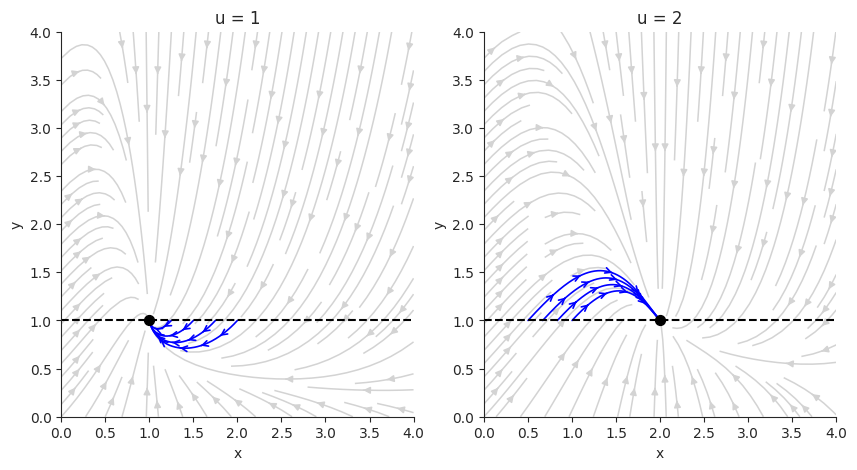

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_u1_u2_streamlines.pdf


In [72]:
# u=1: perturbations in x relax back to SS;  u=2: trajectories starting at/below SS(u=1)
axis_limits = [0, 4, 0, 4]
x_ss1, y_ss1 = steady_state(1.0)
x_ss2, y_ss2 = steady_state(2.0)

fig, axs = plt.subplots(figsize=(10, 5), ncols=2)

ax = axs[0]
draw_field(ax, 1.0, axis_limits)
for plus_x in np.linspace(0, 1, 5):
    draw_trajectory(ax, 1.0, [x_ss1 + plus_x, y_ss1])
ax.scatter([x_ss1], [y_ss1], color='black', zorder=10, s=50)
ax.set_title('u = 1')

ax = axs[1]
draw_field(ax, 2.0, axis_limits)
for minus_x in np.linspace(0, 0.5, 4):
    draw_trajectory(ax, 2.0, [x_ss1 - minus_x, y_ss1])
ax.scatter([x_ss2], [y_ss2], color='black', zorder=10, s=50)
ax.set_title('u = 2')

for ax in axs:
    sns.despine(ax=ax)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.axhline(1, color='black', ls='--')
    ax.set_xlim(axis_limits[:2])
    ax.set_ylim(axis_limits[2:])

plt.show()
save_fig(fig, 'figure5_SI_phase_u1_u2_streamlines.pdf')

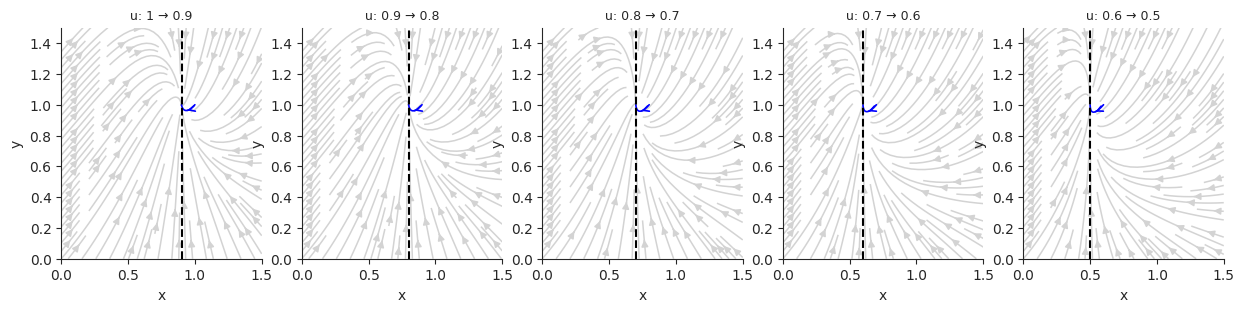

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_stepwise_decrease.pdf


In [73]:
# Lower u stepwise 1 → 0.5: each panel is the trajectory from the previous SS to the next one
us = [1, 0.9, 0.8, 0.7, 0.6, 0.5]
limits = [0, 1.5, 0, 1.5]

fig, axs = plt.subplots(figsize=(15, 3), ncols=5)

for i, ax in enumerate(axs):
    draw_field(ax, us[i + 1], limits)
    draw_trajectory(ax, us[i + 1], list(steady_state(us[i])))
    ax.axvline(steady_state(us[i + 1])[0], color='black', ls='--')
    ax.set_title(f'u: {us[i]} → {us[i + 1]}', fontsize=9)

for ax in axs:
    sns.despine(ax=ax)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_xlim(limits[:2])
    ax.set_ylim(limits[2:])

plt.show()
save_fig(fig, 'figure5_SI_phase_stepwise_decrease.pdf')

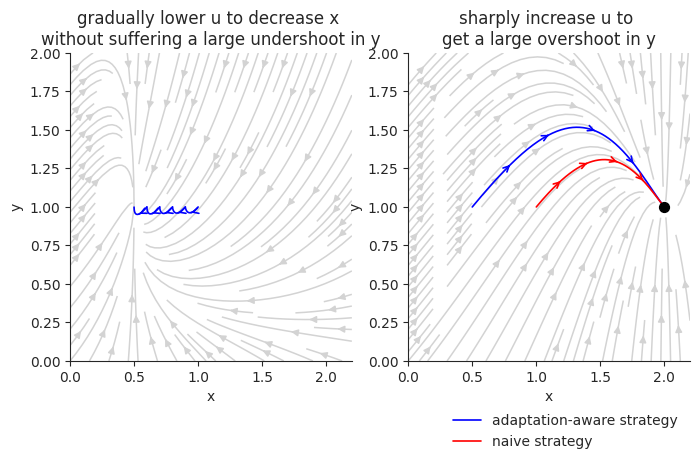

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_gradual_vs_sharp.pdf


In [74]:
# Left: gradual (stepwise) decrease of u avoids a large undershoot in y
# Right: sharp increase of u from a lowered SS gives a large overshoot in y
us = [1, 0.9, 0.8, 0.7, 0.6, 0.5]
limits = [0, 2.2, 0, 2]

fig, axs = plt.subplots(figsize=(8, 4), ncols=2)

ax = axs[0]
draw_field(ax, 0.5, limits)
for i in range(len(us) - 1):
    draw_trajectory(ax, us[i + 1], list(steady_state(us[i])))
ax.set_title('gradually lower u to decrease x \nwithout suffering a large undershoot in y')

ax = axs[1]
draw_field(ax, 2.0, limits)
draw_trajectory(ax, 2.0, list(steady_state(0.5)), color='b', label='adaptation-aware strategy')
draw_trajectory(ax, 2.0, list(steady_state(1.0)), color='red', label='naive strategy')
ax.scatter([steady_state(2.0)[0]], [steady_state(2.0)[1]], color='black', zorder=10, s=50)
ax.set_title('sharply increase u to \nget a large overshoot in y')
ax.legend(frameon=False, bbox_to_anchor=(1.0, -0.13))

for ax in axs:
    sns.despine(ax=ax)
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.show()
save_fig(fig, 'figure5_SI_phase_gradual_vs_sharp.pdf')

### Parameter dependence of the phase portrait (u = 1)
*(from `OLD/test_iffl.ipynb`)*

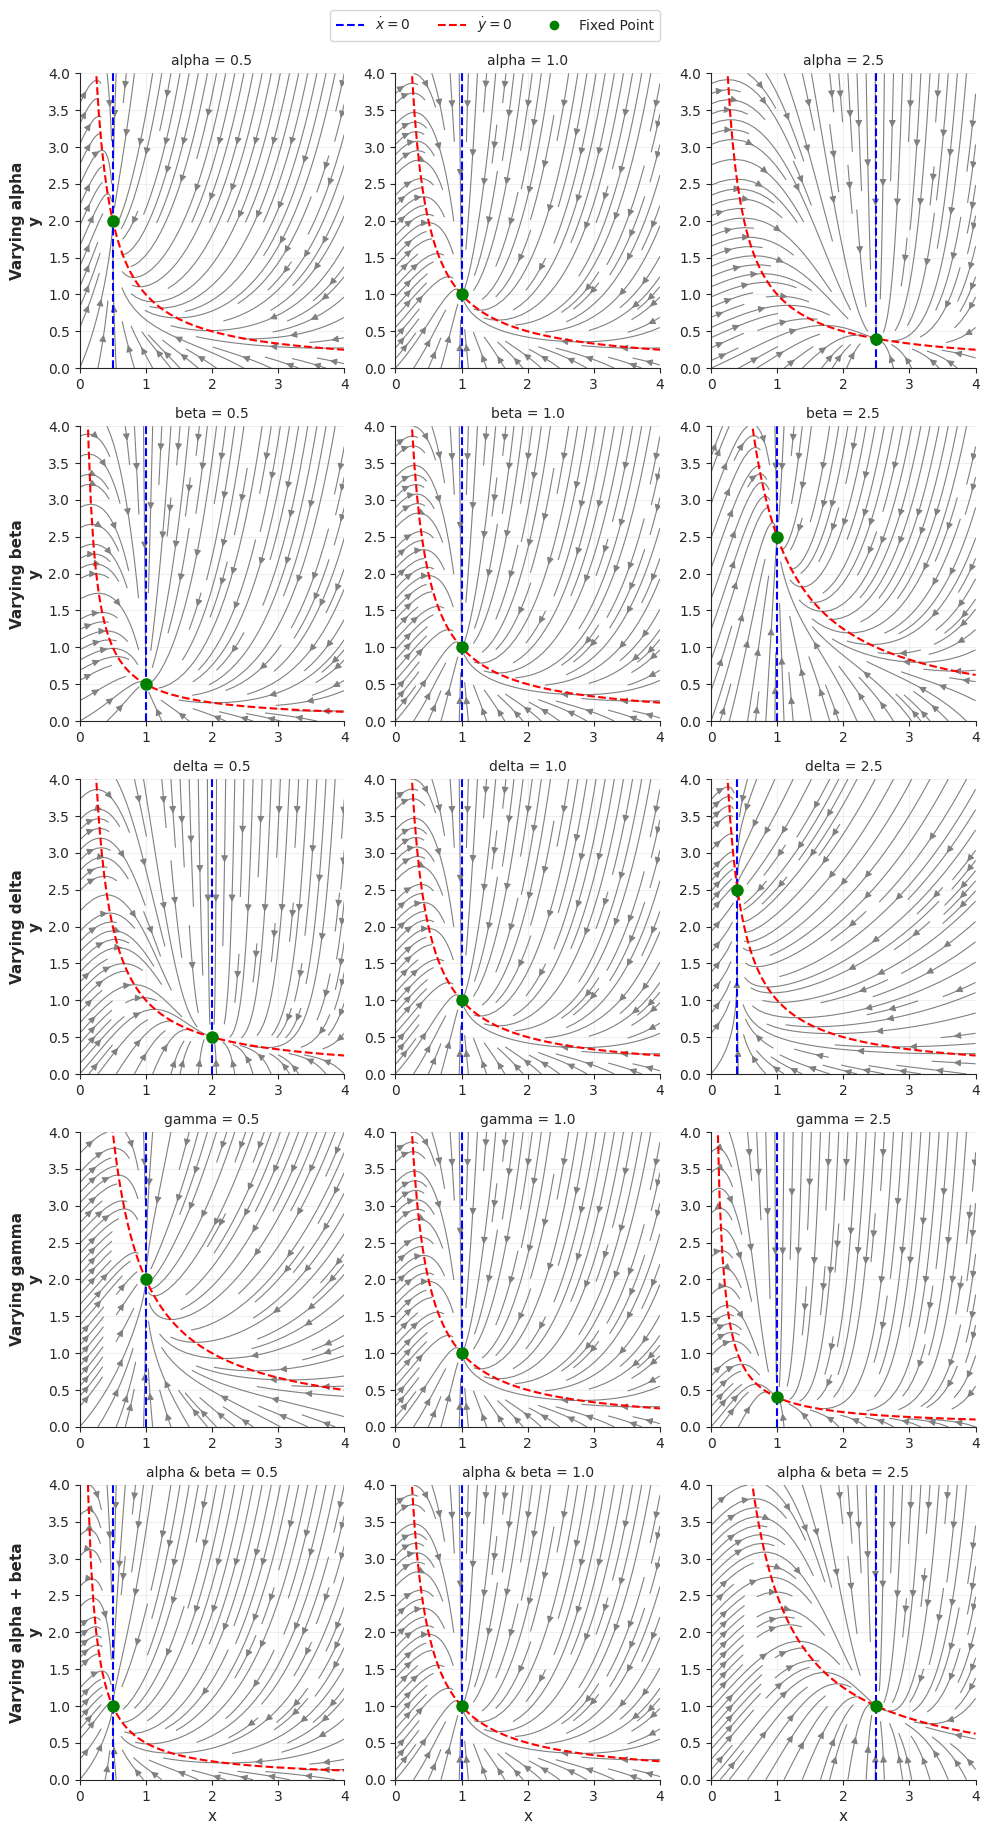

Figure saved to /home/amir/RL/autodiff-control/plots/figure5_SI_phase_parameter_grid.pdf


In [75]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Base parameters
base_params = {'alpha': 1.0, 'beta': 1.0, 'delta': 1.0, 'gamma': 1.0}
u = 1.0

# 2. Define Variations (Now with 5 rows)
# The last tuple 'alpha_beta' will trigger simultaneous changes
variations = [
    ('alpha', [0.5, 1.0, 2.5]),
    ('beta', [0.5, 1.0, 2.5]),
    ('delta', [0.5, 1.0, 2.5]),
    ('gamma', [0.5, 1.0, 2.5]),
    ('alpha_beta', [0.5, 1.0, 2.5]) # New Row
]

# 3. Setup Plot Grid (5 rows, 3 columns)
fig, axes = plt.subplots(5, 3, figsize=(10, 18))

# 4. Simulation Loop
for row_idx, (param_name, values) in enumerate(variations):
    for col_idx, val in enumerate(values):
        ax = axes[row_idx, col_idx]
        
        # Reset to base parameters
        params = base_params.copy()
        
        # Apply the variation
        if param_name == 'alpha_beta':
            # Multiply both base alpha and beta by the value
            params['alpha'] = base_params['alpha'] * val
            params['beta'] = base_params['beta'] * val
            title_str = f'alpha & beta = {val}'
        else:
            # Set the specific parameter
            params[param_name] = val
            title_str = f'{param_name} = {val}'
        
        # Extract for cleaner equations
        a = params['alpha']
        b = params['beta']
        d = params['delta']
        g = params['gamma']
        
        # Create Grid
        x_range = np.linspace(0, 4, 20)
        y_range = np.linspace(0, 4, 20)
        X, Y = np.meshgrid(x_range, y_range)
        
        # Calculate Vector Field
        # dx/dt = a*u - d*x
        DX = (a * u) - (d * X)
        # dy/dt = b*u - g*x*y
        DY = (b * u) - (g * X * Y)
        
        # Streamplot
        ax.streamplot(X, Y, DX, DY, color='gray', density=1, arrowsize=1.0, linewidth=0.8)
        
        # Plot Nullclines
        # x-nullcline (dx/dt = 0): x = a*u/d
        x_null = (a * u) / d
        ax.axvline(x_null, color='b', linestyle='--', label=r'$\dot{x}=0$')
        
        # y-nullcline (dy/dt = 0): y = b*u / (g*x)
        # Avoid division by zero
        x_line = np.linspace(0.05, 4, 100)
        y_line = (b * u) / (g * x_line)
        ax.plot(x_line, y_line, 'r--', label=r'$\dot{y}=0$')
        
        # Plot Fixed Point
        fixed_y = (b * u) / (g * x_null)
        ax.plot(x_null, fixed_y, 'go', markersize=8, zorder=5)
        
        # Formatting
        ax.set_xlim(0, 4)
        ax.set_ylim(0, 4)
        ax.set_title(title_str, fontsize=10)
        ax.grid(True, alpha=0.3)
        sns.despine(ax=ax)
        
        # Label rows and columns
        if col_idx == 0:
            row_label = param_name.replace('_', ' + ')
            ax.set_ylabel(f'Varying {row_label}\ny', fontsize=11, fontweight='bold')
        if row_idx == 4: # Last row
            ax.set_xlabel('x', fontsize=11)

# Add a single legend to the top of the figure
handles, labels = axes[0, 0].get_legend_handles_labels()
# Add a dummy handle for the Fixed Point since we plotted it directly
from matplotlib.lines import Line2D
fixed_point_proxy = Line2D([0], [0], color='w', marker='o', markerfacecolor='g', markersize=8, label='Fixed Point')
handles.append(fixed_point_proxy)
labels.append('Fixed Point')

fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()
save_fig(fig, 'figure5_SI_phase_parameter_grid.pdf')